# JPAMB experiment evaluation

Compare Jev, Heuristic, and Run-all on the same 47 Java methods.
The analysis uses saved experiment data and makes no Jev API calls.
Change `CSV_PATH` in the first cell to evaluate another three-strategy run.

The notes below describe the saved run `experiment-2026-11-27T12-59-46Z-elfy2r7f`.
It contains 47 matched methods per strategy, with three analysis passes per
method. If you change the CSV, rerun the cells and revisit the run-specific
figures quoted in these notes.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

CSV_PATH = Path("reports/experiment-2026-11-27T12-59-46Z-elfy2r7f/methods.csv")
if not CSV_PATH.is_file():
    CSV_PATH = Path("..") / CSV_PATH

df = pd.read_csv(CSV_PATH)
strategies = ["jev", "heuristic", "run-all"]
names = {"jev": "Jev", "heuristic": "Heuristic", "run-all": "Run-all"}
colors = ["#167568", "#BC7131", "#43649B"]
passes = (1, 2, 3)
if set(df["strategy"]) != set(strategies) or df.duplicated(["strategy", "method_id"]).any():
    raise ValueError("Expected one row per strategy and method for all three strategies.")
if df.groupby("method_id")["strategy"].nunique().ne(3).any():
    raise ValueError("The strategies must cover the same methods.")

df["method"] = df["method_id"].str.removeprefix("jpamb.cases.")
df["group"] = df["method"].str.split(":").str[0].str.rsplit(".", n=1).str[0]
df["analyzers"] = df["selected_analyzers"].map(json.loads)
df["expected"] = df["expected_outcomes"].map(json.loads)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.axisbelow": True})

## Suite scores and timing

Selection is charged once. Analysis time is the mean of three passes with the
same analyzer choices. Their sum excludes process startup, scoring, and report
writing. The pass range describes analysis timing variation within this run.

,Selection,Analysis,Total,Score
strategy,,,,
Jev,8.902,4.293,13.196,185.737
Heuristic,0.006,2.808,2.814,208.594
Run-all,0.000,6.034,6.034,193.198


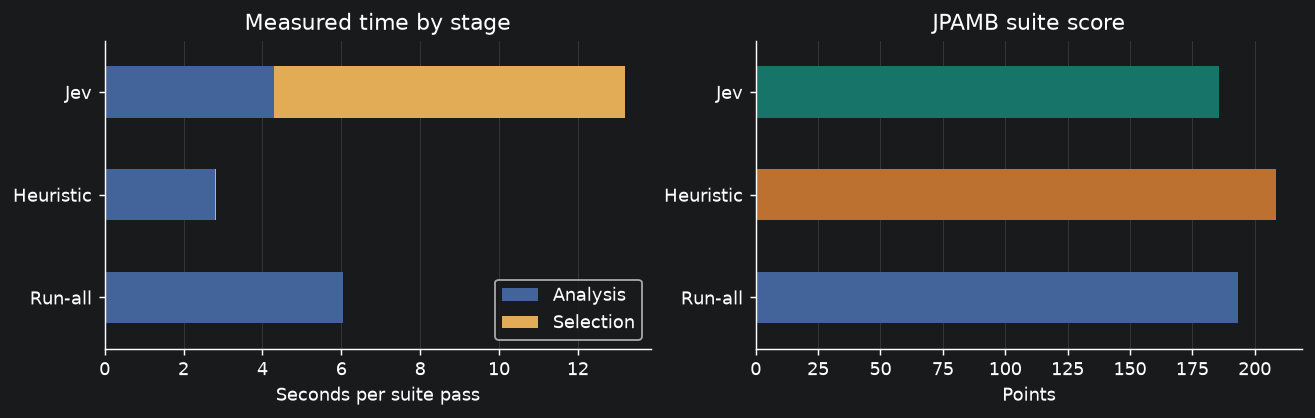

,Pass 1 (s),Pass 2 (s),Pass 3 (s),Range (s)
strategy,,,,
Jev,4.2719,4.2819,4.3261,0.0541
Heuristic,2.8161,2.8126,2.7947,0.0213
Run-all,6.0382,6.0378,6.0265,0.0117


**Jev versus run-all.** Analysis time saved: **1.74 s**. Change in selection-plus-analysis time: **+7.16 s**.

In [2]:
total = df.groupby("strategy").agg(
    Selection=("selection_seconds", "sum"),
    Analysis=("mean_analysis_seconds", "sum"),
    Total=("selection_plus_analysis_seconds", "sum"),
    Score=("jpamb_score", "sum"),
).reindex(strategies).rename(index=names)
display(total.round(3))

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.1), layout="constrained")
total[["Analysis", "Selection"]].plot.barh(
    stacked=True, color=["#43649B", "#E2AC56"], ax=a)
total["Score"].plot.barh(color=colors, ax=b)
a.set(title="Measured time by stage", xlabel="Seconds per suite pass", ylabel="")
b.set(title="JPAMB suite score", xlabel="Points", ylabel="")
for ax in (a, b):
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
plt.show()

timings = df.groupby("strategy")[[f"analysis_seconds_{i}" for i in passes]].sum()
timings.columns = [f"Pass {i} (s)" for i in passes]
timings["Range (s)"] = timings.max(axis=1) - timings.min(axis=1)
display(timings.reindex(strategies).rename(index=names).round(4))

saved = total.at["Run-all", "Analysis"] - total.at["Jev", "Analysis"]
net = total.at["Jev", "Total"] - total.at["Run-all", "Total"]
display(Markdown(
    f"**Jev versus run-all.** Analysis time saved: **{saved:.2f} s**. "
    f"Change in selection-plus-analysis time: **{net:+.2f} s**."
))

### Reading the suite table and charts

- **Selection** adds the recorded selector duration for the 47 methods once.
  Jev's 8.902 s comes from the saved selector run and includes the API wait. The heuristic used 0.006 s, and Run-all
  records zero because its analyzer list is fixed.
- **Analysis** is the mean of the three suite-pass totals. **Total** adds that
  mean to selection time. Each stacked bar shows that breakdown in seconds.
  The other panel shows the sum of the per-method JPAMB scores in points.
- In the second table, **Pass 1–3** are analysis-only totals over the same
  methods. **Range** is the highest pass total minus the lowest. For example,
  Jev's three analysis passes span 4.2719–4.3261 s, a spread of 0.0541 s.
  The selector was measured once, so the table tells us only how analysis time
  varied across the passes.

**What this run shows.** Jev cut analysis time by 28.85% relative to Run-all
(4.293 s versus 6.034 s). Including selection, Jev took 13.196 s, or 7.162 s
longer than Run-all. Heuristic had both the shortest measured total (2.814 s)
and the highest JPAMB score (208.594). Run-all scored 193.198 and Jev 185.737.
Heuristic changed its analyzer lists on eight of the 47 methods compared with
the November 25 run. The paired comparison below examines the accompanying
prediction change.

## Results by Java method group

Scores are averaged within each class using the original full-suite JPAMB
calibration. Timing includes selection and mean analysis. Group sizes matter
when interpreting the differences.

methods  score   time
group     strategy                        
Arrays    heuristic       12  5.163  0.093
          jev             12  4.598  3.741
          run-all         12  5.178  1.853
Calls     heuristic        6  4.189  0.013
          jev              6  4.293  1.970
          run-all          6  4.231  0.539
Dependent heuristic        4  3.796  0.302
          jev              4  4.356  1.099
          run-all          4 -3.706  0.461
Loops     heuristic        4 -0.168  2.041
          jev              4  1.446  2.077
          run-all          4  1.284  2.329
Simple    heuristic       19  5.428  0.144
          jev             19  3.731  3.702
          run-all         19  5.473  0.545
Strings   heuristic        1 -1.586  0.009
          jev              1  5.568  0.234
          run-all          1  5.604  0.063
Tricky    heuristic        1  5.453  0.212
          jev              1  5.137  0.373
          run-all          1  5.771  0.244

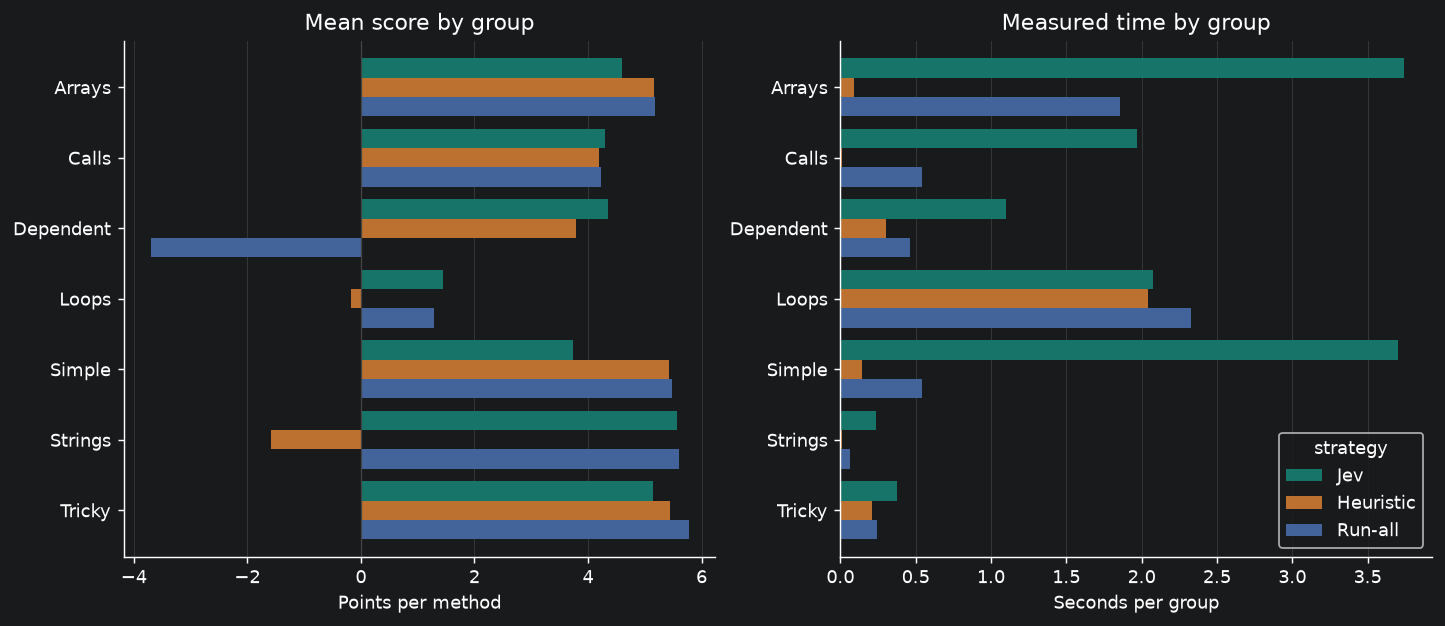

In [3]:
groups = df.groupby(["group", "strategy"]).agg(
    methods=("method_id", "size"),
    score=("jpamb_score", "mean"),
    time=("selection_plus_analysis_seconds", "sum"),
)
display(groups.round(3))
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.7), layout="constrained")
for metric, ax, title, unit in [
    ("score", a, "Mean score by group", "Points per method"),
    ("time", b, "Measured time by group", "Seconds per group"),
]:
    groups[metric].unstack().reindex(columns=strategies).rename(columns=names).plot.barh(
        color=colors, ax=ax, width=0.82)
    ax.set(title=title, xlabel=unit, ylabel="")
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
a.axvline(0, color="#444444", linewidth=0.7)
a.get_legend().remove()
plt.show()

### Reading the group table and charts

Each row covers one strategy within a Java benchmark class. **Methods** is the
number of distinct methods in the class. **Score** is the mean JPAMB score per
method. **Time** is the sum of selection plus mean analysis seconds for the
group. A time bar can be longer because the class has more methods, because
the individual methods take longer, or both. Negative score bars are possible
when penalties outweigh rewards.

**What this run shows.** On **Arrays** (12 methods), Jev averaged 4.598 points
per method, compared with 5.163 for Heuristic and 5.178 for Run-all. Jev
also took longer overall for this group (3.741 s versus 1.853 s for Run-all).
On **Loops** (4 methods), Jev had the highest mean score (1.446) and took
2.077 s compared with 2.329 s for Run-all and 2.041 s for Heuristic. For
**Dependent** (4 methods), Run-all's mean fell to −3.706 because of the
penalty on `normalizedDistance`. Jev and Heuristic averaged 4.356 and 3.796
respectively. **Strings** and **Tricky** each cover one method.

## Outcome discovery and prediction agreement

A definitive answer agrees with the annotations when it predicts `yes` for a
listed outcome or `no` for an unlisted outcome. `Maybe` remains unresolved.
The tables average across the three passes.

status,Agrees,Disagrees,Unresolved
strategy,,,
Jev,143.0,0.0,139.0
Heuristic,165.0,0.0,117.0
Run-all,197.0,1.0,84.0


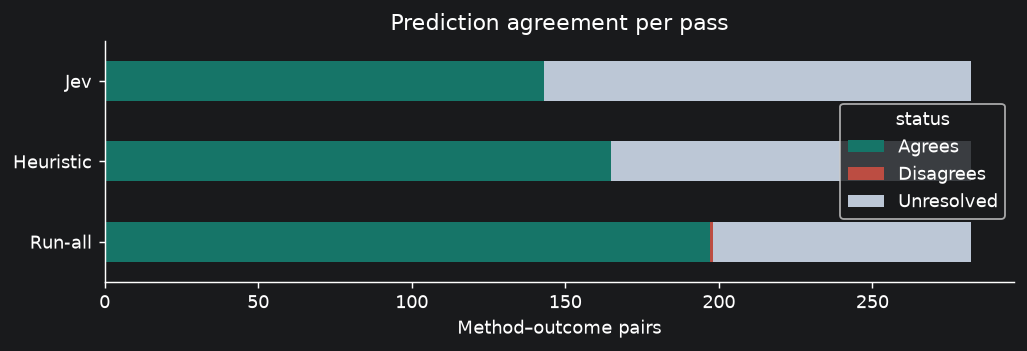

Predicted yes  Listed
outcome         strategy                        
*               heuristic            0.0     3.0
                jev                  0.0     3.0
                run-all              0.0     3.0
assertion error heuristic           19.0    20.0
                jev                 19.0    20.0
                run-all             19.0    20.0
divide by zero  heuristic            5.0     6.0
                jev                  4.0     6.0
                run-all              5.0     6.0
null pointer    heuristic            3.0     3.0
                jev                  3.0     3.0
                run-all              3.0     3.0
ok              heuristic           31.0    34.0
                jev                 25.0    34.0
                run-all             32.0    34.0
out of bounds   heuristic            4.0     4.0
                jev                  4.0     4.0
                run-all              4.0     4.0

In [4]:
records = []
for row in df.itertuples(index=False):
    for number in passes:
        predictions = json.loads(getattr(row, f"predictions_{number}"))
        for outcome, prediction in predictions.items():
            expected = outcome in row.expected
            status = "Unresolved" if prediction == "maybe" else (
                "Agrees" if (prediction == "yes") == expected else "Disagrees"
            )
            records.append((row.strategy, row.method, outcome, expected, prediction, status))

pred = pd.DataFrame(records, columns=[
    "strategy", "method", "outcome", "listed", "prediction", "status",
])
agreement = pd.crosstab(pred.strategy, pred.status).reindex(
    index=strategies, columns=["Agrees", "Disagrees", "Unresolved"], fill_value=0
) / len(passes)
display(agreement.rename(index=names))
ax = agreement.rename(index=names).plot.barh(
    stacked=True, color=["#167568", "#BC4D42", "#BCC7D6"], figsize=(8, 2.8))
ax.set(title="Prediction agreement per pass", xlabel="Method–outcome pairs", ylabel="")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

listed = pred[pred.listed].assign(found=lambda x: x.prediction.eq("yes"))
discovery = listed.groupby(["outcome", "strategy"]).found.agg(["sum", "count"]) / len(passes)
display(discovery.rename(columns={"sum": "Predicted yes", "count": "Listed"}))

### Reading the agreement chart and outcome table

The chart gives equal weight to each of the **282 method–outcome pairs per
pass** (47 methods × 6 possible outcomes). An unresolved prediction is a
`maybe`. A definitive disagreement marks a conflict with the recorded labels,
which may omit a real behavior. The predictions were identical across all
three passes, so the averages here also describe each individual pass.

**Predicted yes / Listed** answers a narrower question. Its denominator is
the count of methods with that outcome in the benchmark annotations, and its
numerator is how many of those methods the strategy predicted `yes` for.
For example, Jev found normal completion on **25 of 34** listed methods,
compared with **31 of 34** for the heuristic and **32 of 34** for Run-all.
All three predicted `yes` for **19 of 20** listed assertion errors. The
`*` row represents nontermination, and none of the strategies predicted
`yes` for any of the three listed cases.

**Why this matters.** Jev had 143 definitive agreements and 139 unresolved
pairs. Heuristic had 165 agreements and 117 unresolved pairs. Run-all had 197
agreements, 84 unresolved pairs, and the sole definitive disagreement.
Run-all agreed with more annotations, while Heuristic earned the highest
calibrated JPAMB score.

## Paired score differences and benchmark-label sensitivity

Scores can differ even when predictions agree because JPAMB calibrates the
strategies separately. The sensitivity check subtracts one method's score contribution from each
strategy's original score. A corrected benchmark would require recomputing
calibration and scores.

In [5]:
scores = df.pivot(index="method", columns="strategy", values="jpamb_score")
delta = scores[["heuristic", "run-all"]].rsub(scores["jev"], axis=0)
display(pd.DataFrame({
    "Jev higher": (delta > 1e-9).sum(),
    "Tie": (delta.abs() <= 1e-9).sum(),
    "Jev lower": (delta < -1e-9).sum(),
    "Full-suite gap": delta.sum(),
    "Gap without normalizedDistance": delta.drop(
        index="Dependent.normalizedDistance:(II)I", errors="ignore").sum(),
}).rename(index=names).round(3))
display(pred[pred.status.eq("Disagrees")].drop_duplicates().reset_index(drop=True))

examples = [
    "Arrays.arrayInBounds:()V",
    "Simple.checkBeforeAssert:(I)V",
    "Strings.sayHello:(Ljava/lang/String;)V",
    "Dependent.normalizedDistance:(II)I",
]
display(df.loc[df.method.isin(examples),
               ["method", "strategy", "analyzers", "predictions_1", "jpamb_score"]]
        .sort_values(["method", "strategy"]))

,Jev higher,Tie,Jev lower,Full-suite gap,Gap without normalizedDistance
strategy,,,,,
Heuristic,11,0,36,-22.857,-23.109
Run-all,18,0,29,-7.461,-39.227


,strategy,method,outcome,listed,prediction,status
0,run-all,Dependent.normalizedDistance:(II)I,divide by zero,False,yes,Disagrees


,method,strategy,analyzers,predictions_1,jpamb_score
49,Arrays.arrayInBounds:()V,heuristic,"[static_int, dynamic_small, dynamic_mutation]","{""*"": ""maybe"", ""assertion error"": ""no"", ""divid...",5.863248
2,Arrays.arrayInBounds:()V,jev,[static_int],"{""*"": ""maybe"", ""assertion error"": ""no"", ""divid...",1.150839
96,Arrays.arrayInBounds:()V,run-all,"[static_sign, static_string, static_int, dynam...","{""*"": ""maybe"", ""assertion error"": ""no"", ""divid...",5.802083
67,Dependent.normalizedDistance:(II)I,heuristic,[dynamic_coverage],"{""*"": ""maybe"", ""assertion error"": ""maybe"", ""di...",5.316239
20,Dependent.normalizedDistance:(II)I,jev,"[static_int, dynamic_small, dynamic_coverage]","{""*"": ""maybe"", ""assertion error"": ""no"", ""divid...",5.568345
114,Dependent.normalizedDistance:(II)I,run-all,"[static_sign, static_string, static_int, dynam...","{""*"": ""maybe"", ""assertion error"": ""no"", ""divid...",-26.197917
78,Simple.checkBeforeAssert:(I)V,heuristic,[dynamic_coverage],"{""*"": ""maybe"", ""assertion error"": ""yes"", ""divi...",5.452991
31,Simple.checkBeforeAssert:(I)V,jev,"[static_sign, dynamic_small, dynamic_coverage]","{""*"": ""maybe"", ""assertion error"": ""yes"", ""divi...",5.784173
125,Simple.checkBeforeAssert:(I)V,run-all,"[static_sign, static_string, static_int, dynam...","{""*"": ""maybe"", ""assertion error"": ""yes"", ""divi...",5.770833
92,Strings.sayHello:(Ljava/lang/String;)V,heuristic,"[static_string, dynamic_random]","{""*"": ""maybe"", ""assertion error"": ""yes"", ""divi...",-1.586004


### Reading the paired comparison and case studies

Each row compares Jev with one baseline on the same 47 methods. A positive
gap favors Jev. Against Heuristic, Jev scored higher on **11 methods**
and lower on **36**, for a gap of **−22.857 points**. Against Run-all, Jev
scored higher on **18** and lower on **29**, for a gap of **−7.461 points**.

Run-all predicted divide by zero in `normalizedDistance`, whose annotations
list only normal completion. The project's
[benchmark notes](../README.md#understand-the-score-before-comparing-configurations)
document a concrete witness at `(0, -2147483648)`. Jev and Heuristic predicted
`maybe` for division by zero. Dropping this method's contribution moves the
Jev–Run-all gap from **−7.461** to **−39.227 points**. The Jev–Heuristic gap
moves from **−22.857** to **−23.109 points**. The omission has the greatest
effect on the comparison with Run-all in this run.

Compared with November 25, Heuristic's prediction for division by zero on this
method changed from `yes` to `maybe`. It was the only prediction to change
between the two exports. This avoided the disagreement under the recorded
labels and changed Heuristic's strategy-wide score calibration.

The example table uses predictions from pass one. Read `analyzers` alongside
the prediction that changed.

| Method | What changed in this run |
| --- | --- |
| `Arrays.arrayInBounds` | Jev selected interval analysis alone and left normal completion unresolved. Both baselines predicted `ok = yes`. |
| `Simple.checkBeforeAssert` | Jev included sign analysis and ruled out division by zero, null pointer, and out of bounds. The heuristic left those outcomes unresolved. |
| `Strings.sayHello` | Jev and Run-all predicted `ok = yes`. The heuristic left it unresolved. This is the only string method in the suite. |

## Analyzer usage

Each bar counts how many methods selected an analyzer. A selection records a
request to run that analyzer, even on a method the analyzer cannot handle.

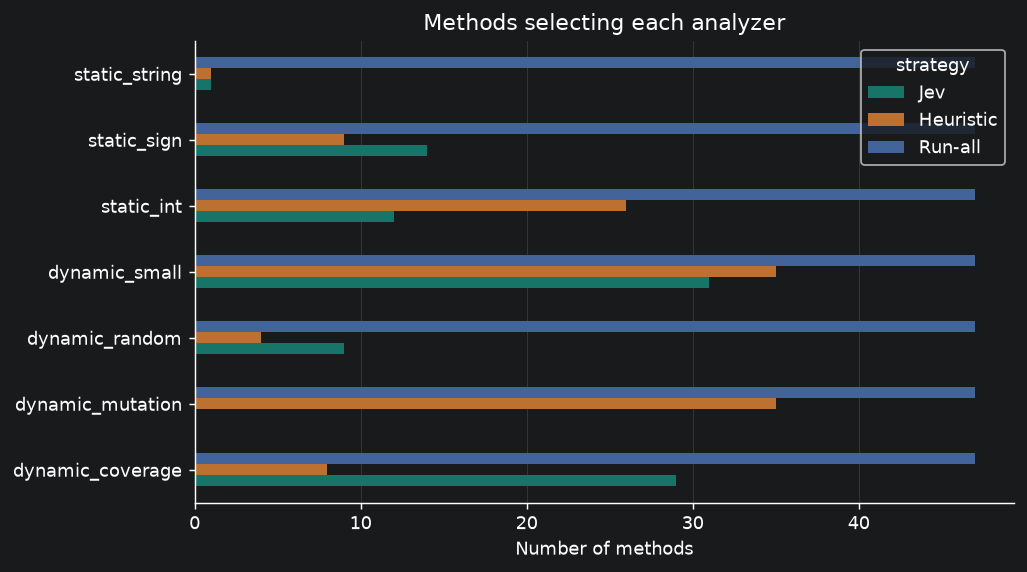

In [6]:
selections = df[["strategy", "analyzers"]].explode("analyzers", ignore_index=True)
usage = pd.crosstab(selections["analyzers"], selections["strategy"]).reindex(columns=strategies, fill_value=0).rename(columns=names)
ax = usage.plot.barh(color=colors, figsize=(8, 4.5))
ax.set(title="Methods selecting each analyzer", xlabel="Number of methods", ylabel="")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

### Reading analyzer usage

The horizontal axis counts **methods**, up to 47. Methods can select more
than one analyzer, so the counts across bars can sum to more than 47. Run-all
requests all seven analyzers on every method. The chart counts requests,
including cases where a technique cannot analyze the method.

**What this run shows.** Jev requested **2.04 analyzers per method** on average,
compared with **2.51** for Heuristic and **7.00** for Run-all. Jev selected
coverage-guided fuzzing for **29 of 47** methods. Heuristic selected
small-scope and mutation fuzzing for **35 methods each** and coverage-guided
fuzzing for **8 methods**. Jev still spent more time in analysis than
Heuristic. These counts describe which analyzers each selector requested.
They cannot attribute runtime or score differences to individual analyzers.